<a href="https://colab.research.google.com/github/Salih-kk/ml-projects/blob/main/titanic_survival.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Titanic Survival Prediction
- **Goal:** predict whether a passenger survived
- **Data:** 891 passengers (seaborn Titanic dataset)
- **Steps:** kept 8 useful columns, filled missing age (median) and embarked (most common), turned text into numbers, trained 3 models
- **Results:** test accuracy: Logistic Regression 0.81, Decision Tree 0.78, Random Forest 0.82 (always guessing "died" gives 0.62)
- **Cross-validation:** Random Forest average 0.814; adding family_size did not help (0.807)
- **Findings:** women survived far more (74% vs 19%) and so did first class (63% vs 24%)
- **What I learned:** (2 lines in your own words, e.g. what the confusion matrix shows)

In [1]:
import seaborn as sns

df = sns.load_dataset("titanic")
print(df.shape)
print(df.isna().sum())
print(df.groupby("sex")["survived"].mean())
print(df.groupby("class")["survived"].mean())   # survival rate by passenger class

(891, 15)
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64
sex
female    0.742038
male      0.188908
Name: survived, dtype: float64
class
First     0.629630
Second    0.472826
Third     0.242363
Name: survived, dtype: float64


/tmp/ipykernel_1184/2330493841.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby("class")["survived"].mean())   # survival rate by passenger class


In [2]:
import pandas as pd
import seaborn as sns

df = sns.load_dataset("titanic")

df = df[["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "embarked"]].copy()
df["age"] = df["age"].fillna(df["age"].median())   # fill with the median (the middle value)
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])   # most common port

print(df.isna().sum().sum())   # total missing values left

df = pd.get_dummies(df, columns=["sex", "embarked"], drop_first=True)   # text -> numbers
print(df.head(3))

0
   survived  pclass   age  sibsp  parch     fare  sex_male  embarked_Q  \
0         0       3  22.0      1      0   7.2500      True       False   
1         1       1  38.0      1      0  71.2833     False       False   
2         1       3  26.0      0      0   7.9250     False       False   

   embarked_S  
0        True  
1       False  
2        True  


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

X = df.drop(columns=["survived"])
y = df["survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)   # train the model (same word as in the housing project)
    pred = model.predict(X_test)
    print(name, "accuracy:", round(accuracy_score(y_test, pred), 3))

print(confusion_matrix(y_test, pred))   # for the last model, Random Forest

Logistic Regression accuracy: 0.81
Decision Tree accuracy: 0.782
Random Forest accuracy: 0.821
[[91 14]
 [18 56]]


without family_size: 0.814
with family_size:    0.807


<Axes: >

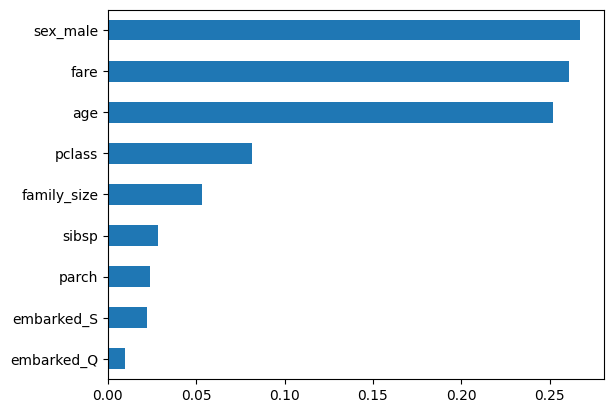

In [4]:
import pandas as pd
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier

y = df["survived"]
rf = RandomForestClassifier(n_estimators=100, random_state=42)

X_old = df.drop(columns=["survived", "family_size"], errors="ignore")
print("without family_size:", cross_val_score(rf, X_old, y, cv=5).mean().round(3))

df["family_size"] = df["sibsp"] + df["parch"] + 1   # plus the passenger themself
X_new = df.drop(columns=["survived"])
print("with family_size:   ", cross_val_score(rf, X_new, y, cv=5).mean().round(3))

rf.fit(X_new, y)
pd.Series(rf.feature_importances_, index=X_new.columns).sort_values().plot(kind="barh")

# ML Projects
My machine learning projects while learning ML, computer vision and speech processing.

## 1. California Housing Price Prediction
Predicts house value from census data using Linear Regression and Random Forest.
- **Result:** Random Forest R2 0.79 (Linear Regression 0.61), average error about $29,500
- **Finding:** income matters most, then location
- **Notebook:** [california_housing.ipynb](california_housing.ipynb)

## 2. Titanic Survival Prediction
Predicts passenger survival with Logistic Regression, Decision Tree and Random Forest.
- **Result:** about 82% test accuracy (always guessing "died" gives 62%)
- **Finding:** sex, fare and age mattered most
- **Notebook:** [titanic_survival.ipynb](titanic_survival.ipynb)